# Notebook 05 — Del difractograma crudo a números que un químico puede leer

## Procesamiento de señal PXRD y extracción de descriptores cristalográficos

**Proyecto:** ALCheMy · **Unidad:** APMU
**Especificación:** [`methodology/ROADMAP_PXRD_CRISTALINIDAD_Y_ML.md`](../methodology/ROADMAP_PXRD_CRISTALINIDAD_Y_ML.md)

---

## Para qué sirve este cuaderno

Un difractograma llega como una curva de varios miles de puntos. Con una curva no
se puede ordenar, filtrar, correlacionar ni entrenar nada: no puedes preguntarle a
una base de datos "dame las síntesis con celda unidad grande y pocos picos".

Este cuaderno construye el puente entre las dos cosas. Convierte cada curva en una
**fila de números interpretables** — cuántas reflexiones hay, cómo de anchas son,
qué fracción del material cristalizó, cómo de grande es la celda unidad — y los
deja escritos en la tabla `pxrd_descriptors`.

Todo lo que verás está calculado sobre **medidas reales de este laboratorio**,
leídas por SQL desde PostgreSQL. No hay datos simulados en ninguna gráfica.

## De dónde salen los datos: la base de datos, siempre

Este cuaderno **nunca abre un fichero `.xrdml`**. Todas las curvas se leen con
`SELECT` desde la tabla `characterization_measurements`.

Esto no es un capricho de estilo. Los ficheros crudos bailan entre directorios, se
renombran, se duplican y se pierden; la base de datos tiene una fila por medida,
con su código de muestra, su hash anti-duplicados y su trazabilidad. Si el número
que sale aquí tiene que ser el mismo que ve el agente RAG, la app web y el modelo
de ML, entonces todos tienen que estar leyendo **la misma fuente de verdad**.

## Qué corrige este cuaderno respecto a la propuesta anterior

| Problema en la propuesta previa | Qué se hace aquí |
|---|---|
| El cuaderno nunca se ejecutó (0 salidas) | Ejecutado de principio a fin contra la BD real |
| Datos sintéticos en casi todas las gráficas | Todas las gráficas usan medidas reales |
| Dos "Etapa 7" en paralelo: una por ficheros y otra por SQL | Una sola vía: SQL |
| λ = 1e7 declarado "calibración canónica" sin calibrar nada | Calibración real (§5) contra blanco, amorfo y cristalino |
| El centro de la joroba amorfa salía ×50 (ángulos > 180°) | Centroide bien integrado (§9) |
| `snr_global` era `max/√max` = `√max`, un duplicado | SNR real: señal neta sobre ruido de Poisson |
| Cristalinidad calculada desde altura de pico (contaba el halo dos veces) | Deconvolución ancho/estrecho (§6) |
| `fwhm_min` se calculaba y no se devolvía | Incluido |
| Contraseña escrita en el propio cuaderno | Credenciales desde `.env` |
| Sin tablas donde guardar nada | `pxrd_descriptors` y `pxrd_labels` creadas y alimentadas (§10) |

---

## Índice

1. Conexión y utilidades
2. Qué hay en la base de datos
3. El problema: cada medida viene en un formato distinto
4. Anatomía de un difractograma real: tres capas superpuestas
5. **Calibración de λ** — la etapa que bloquea todo lo demás
6. Separar el halo amorfo de los picos: por anchura, no con otra línea base
7. Detección de picos con estadística de Poisson
8. El vector de descriptores
9. Los tres errores de cálculo, demostrados con números
10. Escribir en `pxrd_descriptors`
11. Qué dicen los datos


---
# 1. Conexión y utilidades

Cargamos las credenciales desde `.env` (que está en `.gitignore`, así que nunca
viaja a GitHub) y definimos dos ayudantes que se usarán en todo el cuaderno:

- `sql(consulta)` — ejecuta un `SELECT` y devuelve un `DataFrame` de pandas.
- `cargar_curva(...)` — trae una curva concreta y la deja lista sobre la rejilla común.

Toda la matemática vive en `src/pxrd_descriptors.py`. Está en un módulo aparte, y
no copiada dentro del cuaderno, para que el script que procese el corpus completo
use **exactamente las mismas funciones**: si hubiera dos copias, tarde o temprano
una se corregiría y la otra no.


In [1]:
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import psycopg2
from dotenv import load_dotenv

warnings.filterwarnings('ignore')

# El cuaderno se puede lanzar desde la raiz del repo o desde notebooks/
BASE_DIR = os.path.abspath('..') if os.path.isdir('../src') else os.path.abspath('.')
sys.path.insert(0, os.path.join(BASE_DIR, 'src'))
load_dotenv(os.path.join(BASE_DIR, '.env'))

from pxrd_descriptors import (
    GRID_2THETA, WAVELENGTH_CU_KA1, PIPELINE_VERSION,
    DEFAULT_LAMBDA_RIGID, BROAD_WIDTH_DEG, DEFAULT_K_SIGMA,
    resample_to_grid, normalize_by_area, arpls_baseline, broad_component,
    decompose_profile, detect_peaks_poisson, poisson_noise_level,
    extract_descriptors, integrate, DESCRIPTOR_COLUMNS,
)


def conectar():
    """Abre una conexion a PostgreSQL con las credenciales del .env."""
    return psycopg2.connect(
        host=os.getenv('POSTGRES_HOST', 'localhost'),
        port=int(os.getenv('POSTGRES_PORT', 5432)),
        dbname=os.getenv('POSTGRES_DB', 'alchemy_db'),
        user=os.getenv('POSTGRES_USER'),
        password=os.getenv('POSTGRES_PASSWORD'),
    )


def sql(consulta, params=None):
    """Ejecuta un SELECT y devuelve un DataFrame."""
    with conectar() as conn:
        return pd.read_sql_query(consulta, conn, params=params)


def cargar_curva(sample_code=None, file_name=None):
    """
    Trae UNA curva de la base de datos y la deja sobre la rejilla comun.

    Devuelve (x, y) ya recortados al rango angular realmente medido: los puntos
    de la rejilla que caen fuera de lo que el equipo midio se descartan, porque
    inventar cuentas en angulos que nunca se visitaron seria fabricar datos.
    """
    where, params = [], []
    if sample_code:
        where.append('sample_code = %s'); params.append(sample_code)
    if file_name:
        where.append('file_name = %s'); params.append(file_name)
    consulta = f"""
        SELECT data_json->'raw_data'->>'x' AS x,
               data_json->'raw_data'->>'y' AS y
        FROM characterization_measurements
        WHERE technique = 'PXRD' AND {' AND '.join(where)}
        LIMIT 1;
    """
    with conectar() as conn:
        cur = conn.cursor()
        cur.execute(consulta, params)
        fila = cur.fetchone()
    if fila is None:
        raise ValueError(f'No hay medida PXRD para {sample_code or file_name}')
    x_bruto = np.array(json.loads(fila[0]), dtype=float)
    y_bruto = np.array(json.loads(fila[1]), dtype=float)
    rejilla, y_rejilla, valido = resample_to_grid(x_bruto, y_bruto)
    return rejilla[valido], y_rejilla[valido]


# --- Estilo de figuras: mismo aspecto en todo el cuaderno --------------------
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10.5, 'axes.titlesize': 12,
    'axes.labelsize': 11, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'legend.frameon': False,
})
C_CRUDO, C_INSTR, C_AMORFO, C_CRIST, C_PICO = '#37474f', '#b06a3c', '#e8a33d', '#1f7a8c', '#c0392b'

print(f'Conectado. Version del pipeline: {PIPELINE_VERSION}')
print(f'Rejilla comun: {GRID_2THETA[0]:.1f}-{GRID_2THETA[-1]:.2f} grados, '
      f'{len(GRID_2THETA)} puntos, paso {GRID_2THETA[1]-GRID_2THETA[0]:.3f}')


Conectado. Version del pipeline: v1.0
Rejilla comun: 3.0-49.98 grados, 2350 puntos, paso 0.020


---
# 2. Qué hay en la base de datos

Antes de calcular nada, la primera pregunta que hay que hacerle a la fuente de
verdad es sencilla: **¿qué tengo?**

La tabla `characterization_measurements` guarda una fila por medida, sea de la
técnica que sea, y la columna `data_json` contiene la curva completa en formato
JSONB. La columna `measurement_tag` distingue las medidas de síntesis reales de
las **referencias** (el blanco, el patrón del equipo, los precursores), que no son
muestras sino los *patrones de medida* con los que se calibra el método.


In [2]:
inventario = sql("""
    SELECT technique                                   AS tecnica,
           CASE WHEN measurement_tag LIKE 'reference_%'
                THEN measurement_tag ELSE 'muestra_de_sintesis'
           END                                         AS tipo,
           count(*)                                    AS medidas,
           count(DISTINCT sample_code)                 AS muestras_distintas
    FROM characterization_measurements
    WHERE technique IN ('PXRD', 'VT-XRD', 'SC-XRD')
    GROUP BY 1, 2
    ORDER BY medidas DESC;
""")
display(inventario)

total = sql("""
    SELECT count(*) AS medidas_pxrd,
           count(DISTINCT sample_code) AS muestras,
           min(created_at)::date AS primera_carga,
           max(created_at)::date AS ultima_carga
    FROM characterization_measurements
    WHERE technique = 'PXRD';
""")
display(total)


,tecnica,tipo,medidas,muestras_distintas
0,PXRD,muestra_de_sintesis,1859,1803
1,PXRD,reference_precursor,11,11
2,SC-XRD,muestra_de_sintesis,2,2
3,PXRD,reference_blank,1,1
4,PXRD,reference_standard,1,1


,medidas_pxrd,muestras,primera_carga,ultima_carga
0,1872,1816,2026-08-25,2026-08-25


> **Nota sobre `VT-XRD`.** El nombre lleva guion. La propuesta anterior filtraba
> por `'VTXRD'` sin guion, que no coincide con nada: la consulta habría devuelto
> cero filas de temperatura variable sin dar ningún error. Es el tipo de fallo que
> no se ve, porque un resultado vacío se parece mucho a "todavía no hay datos".


---
# 3. El problema: cada medida viene en un formato distinto

Cinco años de laboratorio significan cinco años de criterios distintos. Unos
barridos son rápidos y exploratorios; otros son largos, de calidad Rietveld. Unos
llegan a 35°, otros a 90°. El número de puntos varía casi el triple.

Esto hay que verlo antes de decidir nada, porque es lo que obliga a todo lo que
viene después.


In [3]:
heterogeneidad = sql("""
    SELECT jsonb_array_length(data_json->'raw_data'->'x')      AS n_puntos,
           count(*)                                            AS medidas
    FROM characterization_measurements
    WHERE technique = 'PXRD'
      AND jsonb_array_length(data_json->'raw_data'->'x') > 0
    GROUP BY 1 ORDER BY medidas DESC;
""")
display(heterogeneidad.head(8))

# Rango angular e intensidad maxima de una muestra amplia del corpus
muestra_corpus = sql("""
    SELECT sample_code,
           (data_json->'raw_data'->'x'->>0)::float                                   AS inicio,
           (data_json->'raw_data'->'x'->>(jsonb_array_length(data_json->'raw_data'->'x')-1))::float AS fin,
           jsonb_array_length(data_json->'raw_data'->'x')                            AS n_puntos
    FROM characterization_measurements
    WHERE technique = 'PXRD'
      AND jsonb_array_length(data_json->'raw_data'->'x') > 100;
""")
print(f'{len(muestra_corpus)} medidas analizadas')
print(f"Angulo inicial: de {muestra_corpus['inicio'].min():.1f} a {muestra_corpus['inicio'].max():.1f} grados")
print(f"Angulo final:   de {muestra_corpus['fin'].min():.1f} a {muestra_corpus['fin'].max():.1f} grados")


,n_puntos,medidas
0,2437,1471
1,3960,234
2,3580,160
3,6474,3
4,5808,1
5,2454,1


1870 medidas analizadas
Angulo inicial: de 3.0 a 5.0 grados
Angulo final:   de 35.0 a 90.0 grados


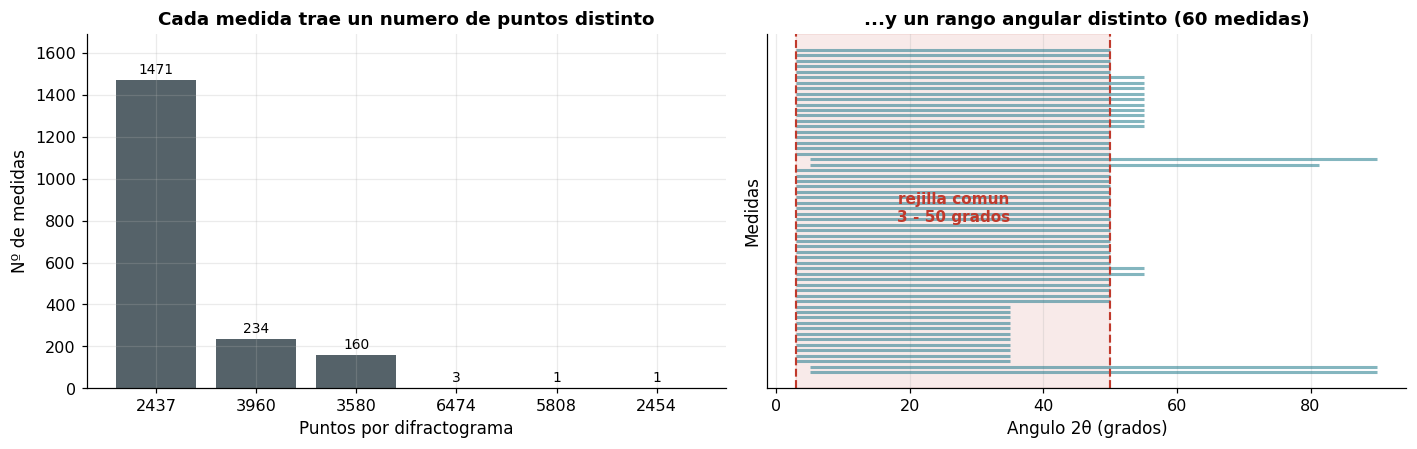

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
top = heterogeneidad.head(6)
barras = ax.bar([str(v) for v in top['n_puntos']], top['medidas'], color=C_CRUDO, alpha=0.85)
ax.bar_label(barras, fmt='%d', padding=2, fontsize=9)
ax.set_title('Cada medida trae un numero de puntos distinto', fontweight='bold')
ax.set_xlabel('Puntos por difractograma'); ax.set_ylabel('Nº de medidas')
ax.margins(y=0.15)

ax = axes[1]
ax.hlines(y=range(len(muestra_corpus.head(60))),
          xmin=muestra_corpus.head(60)['inicio'], xmax=muestra_corpus.head(60)['fin'],
          color=C_CRIST, alpha=0.55, lw=2)
ax.axvspan(3, 50, color=C_PICO, alpha=0.10)
ax.axvline(3, color=C_PICO, ls='--', lw=1.4)
ax.axvline(50, color=C_PICO, ls='--', lw=1.4)
ax.text(26.5, len(muestra_corpus.head(60)) * 0.5, 'rejilla comun\n3 - 50 grados',
        ha='center', va='center', color=C_PICO, fontweight='bold', fontsize=10)
ax.set_title('...y un rango angular distinto (60 medidas)', fontweight='bold')
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Medidas'); ax.set_yticks([])
ax.grid(axis='y', alpha=0)

plt.tight_layout(); plt.show()


**Qué se ve.** A la izquierda, el corpus mezcla difractogramas de ~2.400, ~3.600 y
~6.500 puntos. A la derecha, cada línea horizontal es una medida y su extensión es
el rango angular que barrió: unas empiezan en 3° y otras en 5°, unas acaban en 35°
y otras en 90°.

**Consecuencia.** Dos curvas con distinto número de puntos no se pueden restar,
promediar ni comparar punto a punto. Antes de cualquier cálculo hay que llevarlas
todas a una **rejilla angular común**: de 3° a 50°, con paso de 0,02°.

- ¿Por qué 3–50°? Porque ahí está todo lo estructuralmente relevante en un MOF, sin
  arrastrar la cola de alto ángulo, que es sobre todo ruido.
- ¿Por qué 0,02°? Porque es más fino que el pico más estrecho que el equipo
  resuelve, así que al reinterpolar no se pierde nada.
- Los puntos de la rejilla que caen **fuera** del rango que esa medida barrió se
  descartan. No se extrapolan: inventar cuentas en ángulos que el difractómetro
  nunca visitó sería meter datos falsos en la base de datos.


## 3.1 La segunda incompatibilidad: la escala de cuentas

El número de puntos no es el único problema. Un barrido rápido de cribado acumula
unos pocos miles de cuentas; uno largo de calidad Rietveld acumula cientos de
miles. **El material es el mismo y el patrón es el mismo**, pero los números son
30 o 40 veces más grandes.

Esto no hay que simularlo: la muestra **RS1915** tiene las dos medidas en la base
de datos.


In [5]:
x_rapido, y_rapido = cargar_curva(file_name='24DRX0669-RS1915_CoPy-Test.xrdml')
x_largo,  y_largo  = cargar_curva(file_name='24DRX0669-RS1915_CoPy-Rietveld.xrdml')

print(f'Barrido rapido   (Test):     max = {y_rapido.max():>8,.0f} cuentas')
print(f'Barrido largo (Rietveld):    max = {y_largo.max():>8,.0f} cuentas')
print(f'Factor entre ambos:                {y_largo.max()/y_rapido.max():>8.1f}x')

# Normalizacion por area: cada curva se divide por su propia area integrada
n_rapido = normalize_by_area(y_rapido, x_rapido)
n_largo  = normalize_by_area(y_largo,  x_largo)
print()
print(f'Tras normalizar, el area de cada curva vale exactamente 1:')
print(f'  rapido -> {integrate(n_rapido, x_rapido):.6f}     largo -> {integrate(n_largo, x_largo):.6f}')


Barrido rapido   (Test):     max =    3,416 cuentas
Barrido largo (Rietveld):    max =  112,320 cuentas
Factor entre ambos:                    32.9x

Tras normalizar, el area de cada curva vale exactamente 1:
  rapido -> 1.000000     largo -> 1.000000


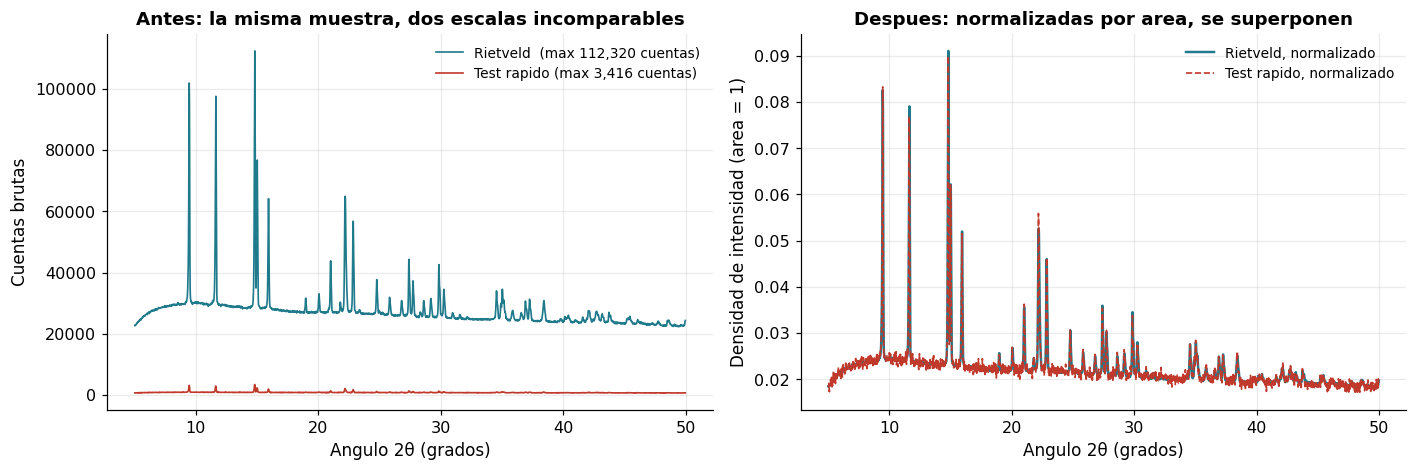

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.plot(x_largo,  y_largo,  color=C_CRIST, lw=1.1, label=f'Rietveld  (max {y_largo.max():,.0f} cuentas)')
ax.plot(x_rapido, y_rapido, color=C_PICO,  lw=1.1, label=f'Test rapido (max {y_rapido.max():,.0f} cuentas)')
ax.set_title('Antes: la misma muestra, dos escalas incomparables', fontweight='bold')
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Cuentas brutas'); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(x_largo,  n_largo,  color=C_CRIST, lw=1.6, label='Rietveld, normalizado')
ax.plot(x_rapido, n_rapido, color=C_PICO,  lw=1.1, ls='--', label='Test rapido, normalizado')
ax.set_title('Despues: normalizadas por area, se superponen', fontweight='bold')
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Densidad de intensidad (area = 1)')
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()


**Qué se ve.** A la izquierda, la curva roja parece plana: no es que la muestra
difracte poco, es que está dibujada junto a otra 33 veces más intensa. A la
derecha, tras dividir cada curva por su propia área integrada, **las dos se
superponen**. Los picos caen en los mismos ángulos con las mismas alturas
relativas, que es lo único que depende del material.

**Por qué por área y no por el máximo.** Dividir por el pico más alto parece más
simple, pero tiene dos fallos graves:

1. Es rehén de un único punto. Si un cristal grande queda orientado de forma
   favorable, ese pico se dispara por *orientación preferente* y toda la curva se
   normaliza contra un artefacto.
2. En una muestra **totalmente amorfa** no hay pico: el máximo es una fluctuación
   de ruido, y normalizarías contra ruido aleatorio.

Dividir por el área usa los ~2.350 puntos a la vez, así que ningún punto suelto
puede estropearlo. Además convierte el difractograma en una **densidad de
probabilidad** (integra 1), que es la forma matemáticamente correcta de comparar
dos distribuciones.


---
# 4. Anatomía de un difractograma real: tres capas superpuestas

Lo que sale del difractómetro no es una sola cosa. Son **tres cosas físicamente
distintas sumadas**, y todo el procesamiento consiste en separarlas:

$$y(2\theta) \;=\; \underbrace{I_{\text{instrumental}}}_{\text{(a) estorbo}} \;+\; \underbrace{I_{\text{amorfo}}}_{\text{(b) SEÑAL}} \;+\; \underbrace{\textstyle\sum_j I_{\text{Bragg},j}}_{\text{(c) SEÑAL}} \;+\; \varepsilon$$

| Capa | Qué es físicamente | Forma | ¿Qué hacemos? |
|---|---|---|---|
| **(a) Fondo instrumental** | Dispersión del aire, portamuestras, fluorescencia, ruido del detector | Monótona, suave, sin estructura | **Se quita.** No dice nada del material |
| **(b) Halo amorfo** | Dispersión difusa de la fase desordenada | Ancha (5–15°) pero **con forma y centro** | **Se conserva. ES SEÑAL** |
| **(c) Picos de Bragg** | Interferencia constructiva de planos cristalinos | Estrechos (< 0,35°) | **Se conserva. ES SEÑAL** |

## El error que hay que evitar a toda costa

La tentación es aplicar una corrección de fondo agresiva y quedarse solo con los
picos. **Eso destruye la información más valiosa del proyecto.**

El halo amorfo es literalmente la medida de *"aquí hay esta cantidad de material
que no cristalizó"*. Si lo borras junto con el fondo instrumental, pierdes la
cuantificación del rendimiento de cristalización — y, peor aún, te llevas por
delante las reflexiones débiles que asoman justo por encima de él, que son las de
las muestras marginales, que son exactamente las interesantes.

Por eso el fondo se separa en dos pasadas y no en una.


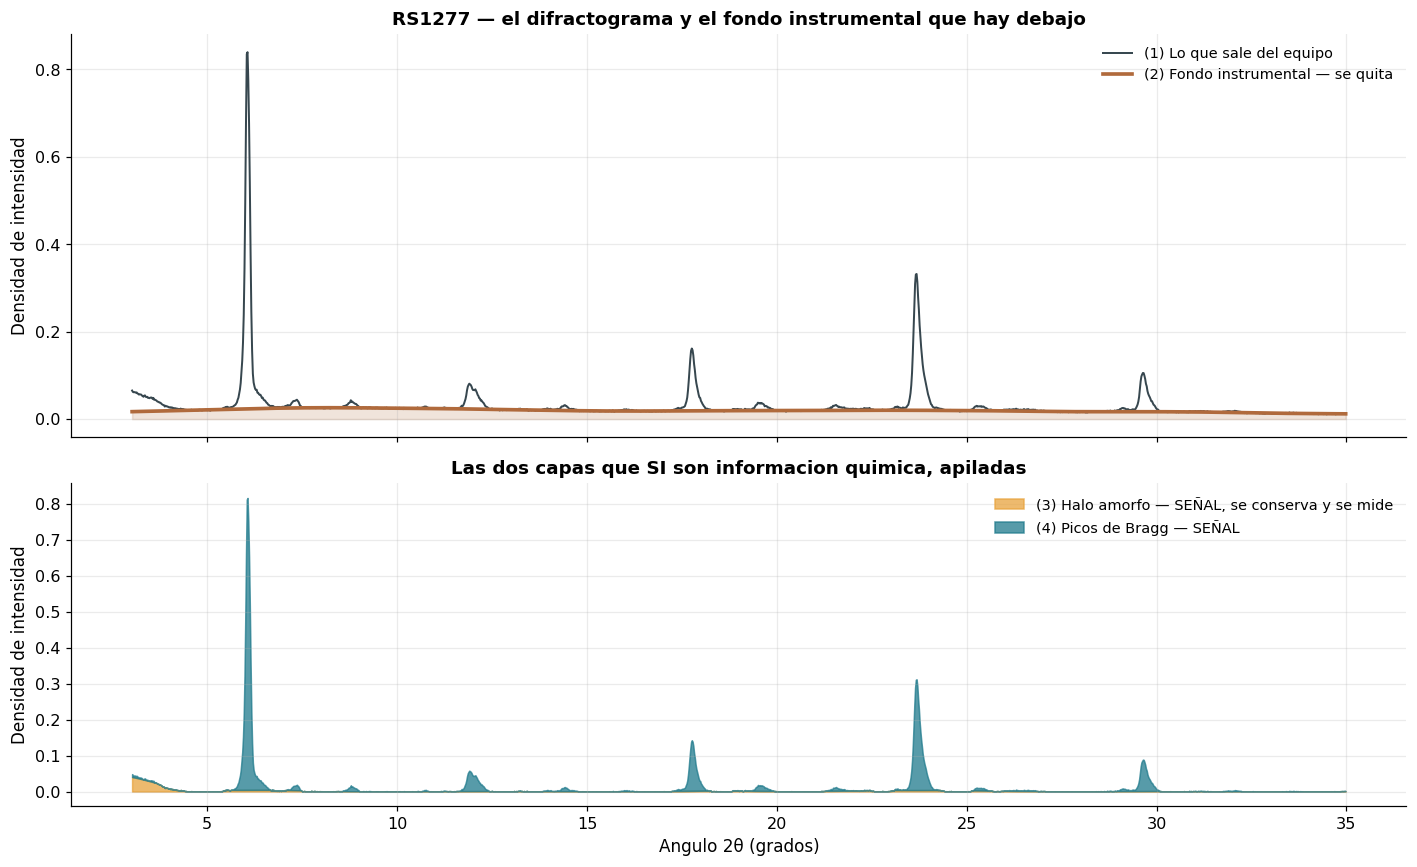

Area cristalina : 0.3181
Area amorfa     : 0.0599
Cristalinidad Xc: 0.842   -> 84.2% del material difractante cristalizo


In [7]:
# Una muestra real con las tres capas bien visibles
x_ej, y_ej = cargar_curva(sample_code='RS1277')
capas = decompose_profile(y_ej, x_ej)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                         gridspec_kw={'height_ratios': [1.25, 1]})

ax = axes[0]
ax.plot(x_ej, capas['normalized'],   color=C_CRUDO, lw=1.3, label='(1) Lo que sale del equipo')
ax.plot(x_ej, capas['instrumental'], color=C_INSTR, lw=2.4, label='(2) Fondo instrumental — se quita')
ax.fill_between(x_ej, 0, capas['instrumental'], color=C_INSTR, alpha=0.18)
ax.set_title('RS1277 — el difractograma y el fondo instrumental que hay debajo', fontweight='bold')
ax.set_ylabel('Densidad de intensidad'); ax.legend(fontsize=9.5, loc='upper right')

ax = axes[1]
ax.fill_between(x_ej, 0, capas['amorphous'], color=C_AMORFO, alpha=0.75,
                label='(3) Halo amorfo — SEÑAL, se conserva y se mide')
ax.fill_between(x_ej, capas['amorphous'], capas['amorphous'] + capas['crystalline'],
                color=C_CRIST, alpha=0.75, label='(4) Picos de Bragg — SEÑAL')
ax.set_title('Las dos capas que SI son informacion quimica, apiladas', fontweight='bold')
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Densidad de intensidad')
ax.legend(fontsize=9.5, loc='upper right')

plt.tight_layout(); plt.show()

a_cri = integrate(capas['crystalline'], x_ej)
a_amo = integrate(capas['amorphous'], x_ej)
print(f'Area cristalina : {a_cri:.4f}')
print(f'Area amorfa     : {a_amo:.4f}')
print(f'Cristalinidad Xc: {a_cri/(a_cri+a_amo):.3f}   -> {100*a_cri/(a_cri+a_amo):.1f}% del material difractante cristalizo')


**Qué se ve.** Arriba, la curva gris es la medida y la banda marrón es el fondo
instrumental que arPLS encuentra por debajo: baja suavemente y no intenta seguir
ningún pico.

Abajo, lo que queda después de restarlo, separado en sus dos componentes químicas:
en **naranja** el halo amorfo (una joroba ancha), en **azul** los picos de Bragg
que se levantan por encima de él. La cristalinidad es simplemente la proporción
entre el área azul y el área total coloreada.

Fíjate en un detalle importante: el azul está **apilado encima** del naranja, no
dibujado desde cero. Eso es justamente lo que hace que la cuenta sea honesta, y lo
veremos en el §6.


---
# 5. Calibración de λ — la etapa que bloquea todo lo demás

## 5.1 Qué hace arPLS y qué significa λ

**arPLS** (*asymmetrically reweighted penalized least squares*, Baek et al.,
*Analyst* 140 (2015) 250-257) ajusta una curva suave por debajo de los datos
minimizando:

$$F(z)=\sum_i w_i\,(y_i-z_i)^2 \;+\; \lambda \sum_i (z_{i-1}-2z_i+z_{i+1})^2$$

- El **primer término** tira de la línea base hacia los datos.
- El **segundo término** penaliza la curvatura: cuanto mayor es $\lambda$, menos se
  le permite doblarse a la línea base.

Y lo de *"reponderado asimétricamente"* es la clave: después de cada iteración se
recalculan los pesos $w_i$ según el residuo. A los puntos que quedan **por encima**
de la línea base (los picos) se les lleva el peso casi a cero, para que la línea
deje de perseguirlos; a los que quedan por debajo (ruido) se les mantiene el peso
completo. Esa asimetría es lo que hace que encuentre el **suelo** del espectro en
lugar de su promedio.

> $\lambda$ es, literalmente, el mando que decide **cuánta información química se
> destruye**. Demasiado bajo, la línea base es tan flexible que se traga el halo
> amorfo. Demasiado alto, es tan rígida que deja fondo sin quitar.

## 5.2 Por qué hay que normalizar ANTES de ajustar la línea base

Hay un detalle que la propuesta anterior no tenía en cuenta y que invalida
cualquier λ elegido a ojo.

λ mide la rigidez **en relación al tamaño de los números que está ajustando**.
Aplicado a cuentas brutas, el mismo λ es una línea base muy rígida en un barrido
de 200 cuentas y muy blanda en uno de 20.000. Es decir: dos medidas del mismo
material se procesarían de forma distinta por un motivo que no tiene nada de
físico, y sus descriptores no serían comparables.

Por eso el orden correcto es: **primero normalizar por área, después ajustar la
línea base**. Así un único λ calibrado significa lo mismo para las 1.859 medidas.

## 5.3 La calibración honesta: tres patrones, tres criterios

Esta es la etapa **E1** del roadmap, la única marcada como bloqueante. Elegir λ a
ojo — o peor, declarar un valor "canónico" sin haberlo medido — convierte todo lo
que viene después en una opinión.

La calibración usa tres patrones reales, **que ya están en la base de datos** con
su `measurement_tag` de referencia:

| Patrón | Criterio | Qué significa fallarlo |
|---|---|---|
| **Blanco** (portamuestras vacío) | El residuo tras corregir debe ser ≈ 0 | Si no baja, λ es demasiado **alto**: deja fondo sin quitar |
| **Muestra amorfa** | La joroba **debe seguir ahí** | Si desaparece, λ es demasiado **bajo**: se comió la señal |
| **Muestra cristalina** | Los picos no deben estrecharse ni perder intensidad | Si se deforman, λ está corrompiendo la FWHM, que es un descriptor |

Barremos λ ∈ {10³ … 10⁸} sobre los tres y miramos los números.


In [8]:
LAMBDAS = [1e3, 1e4, 1e5, 1e6, 1e7, 1e8]

x_blanco, y_blanco = cargar_curva(sample_code='REF-DRX-26376-10-Blanco')
x_amorfo, y_amorfo = cargar_curva(sample_code='RS1334')   # pocos picos, halo dominante
x_crist,  y_crist  = cargar_curva(sample_code='RS1925')   # muy cristalina

filas = []
curvas_blanco, curvas_amorfo = {}, {}

for lam in LAMBDAS:
    # --- criterio 1: el blanco debe quedar en casi nada -----------------
    n_b = normalize_by_area(y_blanco, x_blanco)
    base_b = arpls_baseline(n_b, lam=lam)
    residuo_blanco = integrate(np.maximum(n_b - base_b, 0), x_blanco)
    curvas_blanco[lam] = base_b

    # --- criterio 2: la joroba amorfa debe sobrevivir -------------------
    capas_a = decompose_profile(y_amorfo, x_amorfo, lam_rigid=lam)
    area_amorfa = integrate(capas_a['amorphous'], x_amorfo)
    area_crist_a = integrate(capas_a['crystalline'], x_amorfo)
    xc_amorfo = area_crist_a / (area_crist_a + area_amorfa + 1e-12)
    curvas_amorfo[lam] = capas_a

    # --- criterio 3: los picos no deben deformarse ---------------------
    capas_c = decompose_profile(y_crist, x_crist, lam_rigid=lam)
    ruido_c = poisson_noise_level(y_crist, x_crist)
    picos_c, fwhm_c = detect_peaks_poisson(x_crist, capas_c['crystalline'], ruido_c)

    filas.append({
        'lambda': f'{lam:.0e}',
        'blanco: residuo': round(residuo_blanco, 4),
        'amorfo: area joroba': round(area_amorfa, 4),
        'amorfo: Xc': round(xc_amorfo, 3),
        'cristal: nº picos': len(picos_c),
        'cristal: FWHM med': round(float(np.median(fwhm_c)), 4) if len(fwhm_c) else np.nan,
        'cristal: altura max': round(float(capas_c['crystalline'].max()), 4),
    })

tabla_calibracion = pd.DataFrame(filas)
display(tabla_calibracion)


,lambda,blanco: residuo,amorfo: area joroba,amorfo: Xc,cristal: nº picos,cristal: FWHM med,cristal: altura max
0,1e+03,0.0399,0.0032,0.817,42,0.0843,0.0461
1,1e+04,0.0400,0.0383,0.267,43,0.0859,0.0465
2,1e+05,0.0405,0.0457,0.239,45,0.0871,0.0466
3,1e+06,0.0418,0.0466,0.238,46,0.0871,0.0467
4,1e+07,0.0605,0.0467,0.235,46,0.0870,0.0467
5,1e+08,0.0881,0.0523,0.196,45,0.0874,0.0467


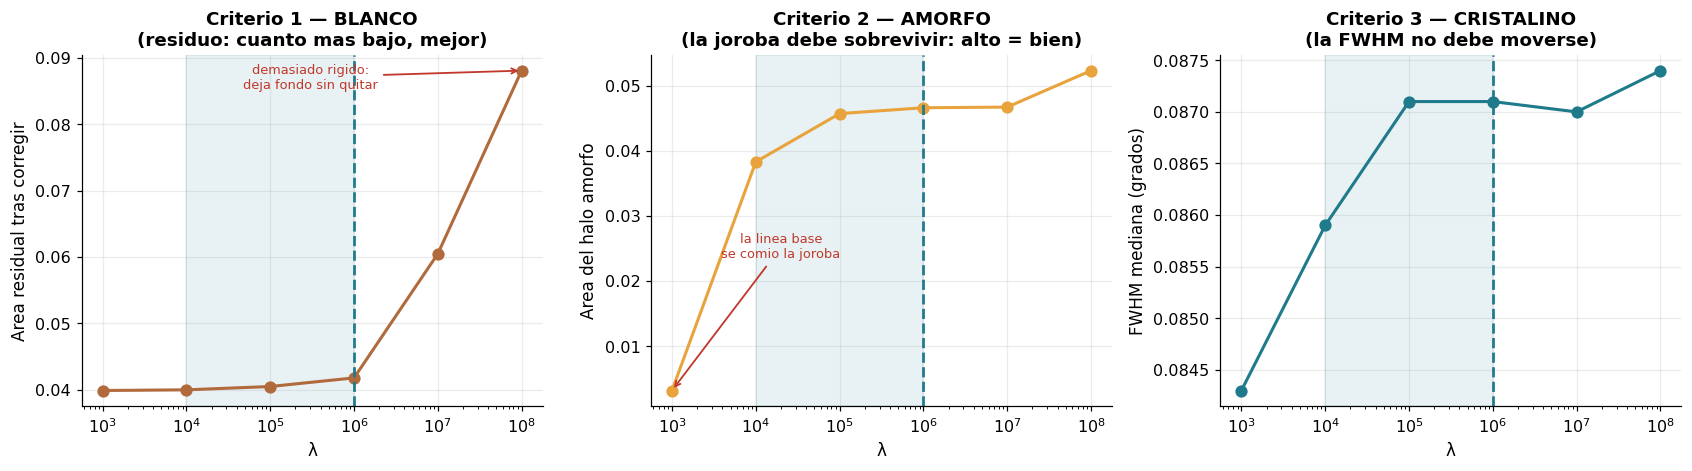

Valor elegido: lambda = 1e+06  (banda sombreada = zona valida por los 3 criterios)


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
lams = np.array(LAMBDAS)

# --- Criterio 1 -------------------------------------------------------
ax = axes[0]
resid = tabla_calibracion['blanco: residuo'].values
ax.plot(lams, resid, 'o-', color=C_INSTR, lw=2, ms=7)
ax.set_xscale('log'); ax.set_title('Criterio 1 — BLANCO\n(residuo: cuanto mas bajo, mejor)', fontweight='bold')
ax.set_xlabel('λ'); ax.set_ylabel('Area residual tras corregir')
ax.annotate('demasiado rigido:\ndeja fondo sin quitar', xy=(1e8, resid[-1]), xytext=(3e5, resid[-1]*0.97),
            fontsize=8.5, color=C_PICO, ha='center',
            arrowprops=dict(arrowstyle='->', color=C_PICO, lw=1.2))

# --- Criterio 2 -------------------------------------------------------
ax = axes[1]
areas = tabla_calibracion['amorfo: area joroba'].values
ax.plot(lams, areas, 'o-', color=C_AMORFO, lw=2, ms=7)
ax.set_xscale('log'); ax.set_title('Criterio 2 — AMORFO\n(la joroba debe sobrevivir: alto = bien)', fontweight='bold')
ax.set_xlabel('λ'); ax.set_ylabel('Area del halo amorfo')
ax.annotate('la linea base\nse comio la joroba', xy=(1e3, areas[0]), xytext=(2e4, areas.max()*0.45),
            fontsize=8.5, color=C_PICO, ha='center',
            arrowprops=dict(arrowstyle='->', color=C_PICO, lw=1.2))

# --- Criterio 3 -------------------------------------------------------
ax = axes[2]
ax.plot(lams, tabla_calibracion['cristal: FWHM med'].values, 'o-', color=C_CRIST, lw=2, ms=7)
ax.set_xscale('log'); ax.set_title('Criterio 3 — CRISTALINO\n(la FWHM no debe moverse)', fontweight='bold')
ax.set_xlabel('λ'); ax.set_ylabel('FWHM mediana (grados)')

for ax in axes:
    ax.axvspan(1e4, 1e6, color=C_CRIST, alpha=0.10)
    ax.axvline(DEFAULT_LAMBDA_RIGID, color=C_CRIST, ls='--', lw=1.8)

plt.tight_layout(); plt.show()
print(f'Valor elegido: lambda = {DEFAULT_LAMBDA_RIGID:.0e}  (banda sombreada = zona valida por los 3 criterios)')


## 5.4 Veredicto de la calibración

Los tres criterios se leen a la vez:

- **λ = 10³ destruye la joroba amorfa.** El área del halo se desploma y, como
  consecuencia directa, la cristalinidad de la muestra amorfa **salta de ~0,24 a
  ~0,82**. Es decir: una muestra que no cristalizó sería registrada en la base de
  datos como mayoritariamente cristalina. Un número perfectamente creíble y
  completamente falso — el peor tipo de error.
- **λ ≥ 10⁷ es demasiado rígido.** El residuo sobre el blanco sube ~50 %: la línea
  base ya no puede seguir la caída del fondo instrumental y deja parte sin quitar.
- **Entre 10⁴ y 10⁶ los tres criterios están satisfechos a la vez.** La joroba está
  en su meseta, el residuo del blanco cerca de su mínimo, y los picos ni se
  estrechan ni pierden altura (FWHM prácticamente constante).

**Se elige λ = 10⁶**, en el centro de esa banda: la joroba ha alcanzado su meseta
completa y el residuo del blanco sigue a menos de un 5 % de su suelo.

> **Esto contradice la propuesta anterior**, que declaraba λ = 10⁷ como
> *"calibración canónica de ALCheMy"* sin haber ejecutado ninguna calibración. Con
> los patrones reales de este laboratorio, 10⁷ está fuera de la zona buena.
> El valor queda guardado en cada fila de `pxrd_descriptors.baseline_lambda`, de
> modo que si algún día se recalibra, se sabrá exactamente qué filas son
> comparables entre sí.


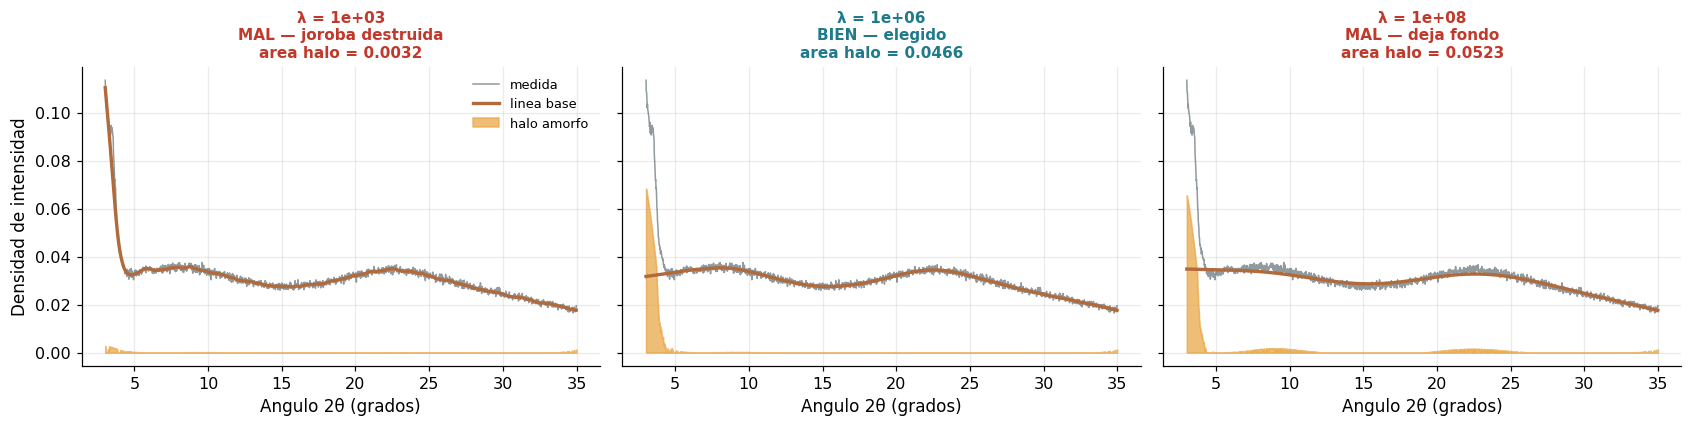

In [10]:
# Lo mismo, pero visto sobre la curva: que le pasa al amorfo con cada lambda
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4), sharey=True)
for ax, lam in zip(axes, [1e3, 1e6, 1e8]):
    capas_a = curvas_amorfo[lam]
    ax.plot(x_amorfo, capas_a['normalized'], color=C_CRUDO, lw=1.0, alpha=0.55, label='medida')
    ax.plot(x_amorfo, capas_a['instrumental'], color=C_INSTR, lw=2.2, label='linea base')
    ax.fill_between(x_amorfo, 0, capas_a['amorphous'], color=C_AMORFO, alpha=0.7, label='halo amorfo')
    area = integrate(capas_a['amorphous'], x_amorfo)
    veredicto = {1e3: 'MAL — joroba destruida', 1e6: 'BIEN — elegido', 1e8: 'MAL — deja fondo'}[lam]
    ax.set_title(f'λ = {lam:.0e}\n{veredicto}\narea halo = {area:.4f}',
                 fontweight='bold', fontsize=10,
                 color=(C_PICO if lam != 1e6 else C_CRIST))
    ax.set_xlabel('Angulo 2θ (grados)')
axes[0].set_ylabel('Densidad de intensidad'); axes[0].legend(fontsize=8.5)
plt.tight_layout(); plt.show()


**Qué se ve.** Con λ = 10³ (izquierda) la línea base marrón se dobla hasta abrazar
la joroba: cuando la restas, el halo naranja casi desaparece y esa muestra amorfa
pasa a parecer cristalina. Con λ = 10⁸ (derecha) la línea base es casi recta y se
queda por debajo del fondo real, dejando sin quitar una parte que no es química.
Con λ = 10⁶ (centro) la línea base sigue el fondo instrumental y **el halo naranja
sobrevive entero**, que es exactamente lo que se busca.


---
# 6. Separar el halo de los picos: por anchura, no con otra línea base

Ya tenemos fuera el fondo instrumental. Lo que queda (`net`) es halo + picos, y
hay que separarlos para poder medir la cristalinidad.

## 6.1 La idea que parece obvia y falla en silencio

La tentación es: *"aplico arPLS otra vez con un λ más blando y lo que salga es el
halo"*. **No funciona, y falla de la peor manera posible: sin dar ningún error.**

arPLS es, por construcción, un estimador de **línea base**: busca el *suelo* de los
datos. Si se lo aplicas a una curva cuyo suelo ya es cero, devuelve aproximadamente
cero. Resultado: área amorfa ≈ 0 y **todas las muestras salen con cristalinidad
1,000**, incluidas las amorfas.

Vamos a verlo, porque es un error instructivo.


In [11]:
x_dem, y_dem = cargar_curva(sample_code='RS1334')      # muestra con halo evidente
capas_dem = decompose_profile(y_dem, x_dem)
net_dem = capas_dem['net']

# (A) El intento fallido: un segundo arPLS blando como "envolvente"
envolvente_arpls = np.maximum(arpls_baseline(net_dem, lam=1e5), 0.0)
area_A = integrate(envolvente_arpls, x_dem)

# (B) Lo correcto: filtro selectivo en ANCHURA (mediana movil)
envolvente_ancha = broad_component(net_dem)
area_B = integrate(envolvente_ancha, x_dem)

area_net = integrate(net_dem, x_dem)
print(f'Area de la señal neta (halo + picos): {area_net:.4f}')
print()
print(f'(A) Segundo arPLS  -> area del halo = {area_A:.4f}   ({100*area_A/area_net:>5.1f}% de la señal)  '
      f'Xc = {1-area_A/area_net:.3f}')
print(f'(B) Filtro anchura -> area del halo = {area_B:.4f}   ({100*area_B/area_net:>5.1f}% de la señal)  '
      f'Xc = {1-area_B/area_net:.3f}')
print()
print(f'El metodo (A) declara esta muestra {100*(1-area_A/area_net):.0f}% cristalina. Mirando la curva se ve que no lo es.')


Area de la señal neta (halo + picos): 0.0612

(A) Segundo arPLS  -> area del halo = 0.0000   (  0.0% de la señal)  Xc = 1.000
(B) Filtro anchura -> area del halo = 0.0466   ( 76.2% de la señal)  Xc = 0.238

El metodo (A) declara esta muestra 100% cristalina. Mirando la curva se ve que no lo es.


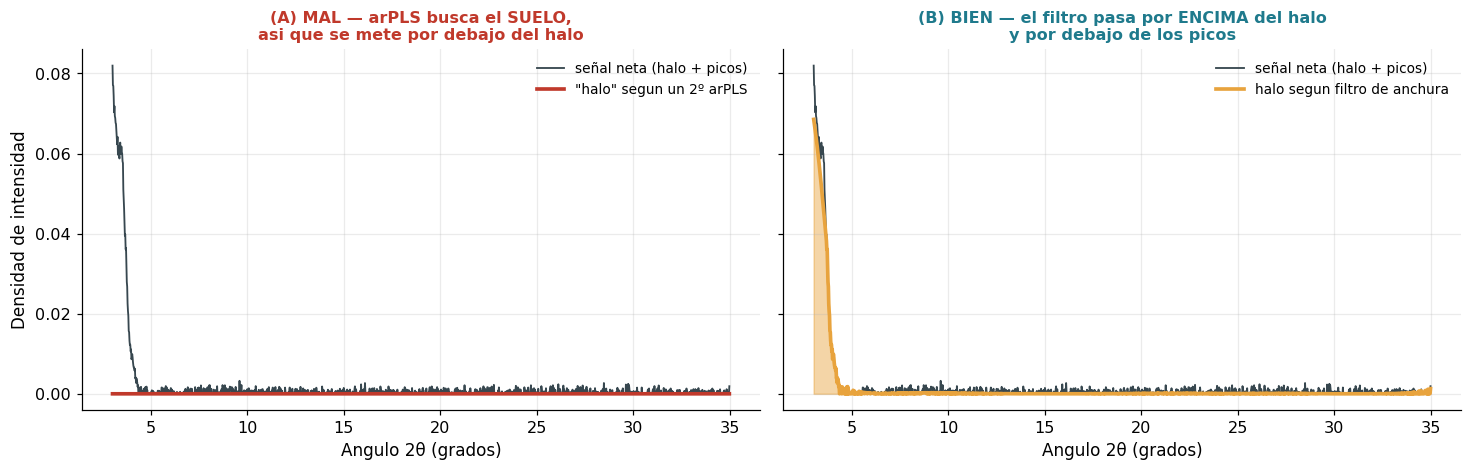

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), sharey=True)

ax = axes[0]
ax.plot(x_dem, net_dem, color=C_CRUDO, lw=1.2, label='señal neta (halo + picos)')
ax.plot(x_dem, envolvente_arpls, color=C_PICO, lw=2.4, label='"halo" segun un 2º arPLS')
ax.fill_between(x_dem, 0, envolvente_arpls, color=C_PICO, alpha=0.25)
ax.set_title('(A) MAL — arPLS busca el SUELO,\nasi que se mete por debajo del halo',
             fontweight='bold', color=C_PICO, fontsize=10.5)
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Densidad de intensidad'); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(x_dem, net_dem, color=C_CRUDO, lw=1.2, label='señal neta (halo + picos)')
ax.plot(x_dem, envolvente_ancha, color=C_AMORFO, lw=2.4, label='halo segun filtro de anchura')
ax.fill_between(x_dem, 0, envolvente_ancha, color=C_AMORFO, alpha=0.45)
ax.set_title('(B) BIEN — el filtro pasa por ENCIMA del halo\ny por debajo de los picos',
             fontweight='bold', color=C_CRIST, fontsize=10.5)
ax.set_xlabel('Angulo 2θ (grados)'); ax.legend(fontsize=9)

plt.tight_layout(); plt.show()


**Qué se ve.** A la izquierda, la curva roja (el segundo arPLS) va pegada al cero:
se ha metido *por debajo* del halo, porque eso es lo que hace una línea base. Todo
lo que queda por encima se contabiliza como cristalino. A la derecha, la curva
naranja **monta sobre el halo** y solo deja fuera los picos estrechos, que es
justamente la separación que buscábamos.

## 6.2 Lo que de verdad distingue el halo de un pico es la ANCHURA

- Una reflexión de Bragg es **estrecha**: FWHM por debajo de ~0,35°.
- Un halo amorfo es **ancho**: FWHM de 5 a 15°.

Así que el filtro tiene que ser selectivo **en anchura**, no en altura. Se usa una
**mediana móvil** con una ventana de 3°:

- Todo lo más estrecho que media ventana (~1,5°) — es decir, **todos los picos** —
  la mediana lo "salta" y desaparece.
- Todo lo mucho más ancho — **el halo** — pasa intacto.

Los 3° están elegidos para caer en el hueco entre ambos mundos: es casi 10 veces
más ancho que el pico más ancho, y 2-5 veces más estrecho que el halo más estrecho.
Después se aplica un suavizado gaussiano suave para quitar el efecto de escalera
que deja la mediana.

Esto es el equivalente práctico de lo que el roadmap describe como *"ajustar
gaussianas anchas a las jorobas que hay bajo los picos cristalinos"*, pero sin un
ajuste no lineal por muestra que podría no converger en alguno de los 1.859
patrones y dejar el proceso a medias.

## 6.3 Y por eso la cristalinidad sale honesta

$$X_c=\frac{A_{\text{cristalino}}}{A_{\text{cristalino}}+A_{\text{amorfo}}}$$

El detalle que importa: el área cristalina se mide **desde el halo hacia arriba**,
no desde cero. Medir la altura del pico desde cero contaría **dos veces** el halo
que hay debajo de cada pico, como si fuera cristalino, e inflaría la cristalinidad
justo en las muestras marginales, que son las que más importan.


---
# 7. Detección de picos con estadística de Poisson

## 7.1 Por qué no vale un umbral fijo

Detectar rayos X es **contar fotones**, y contar sucesos raros sigue una
distribución de Poisson, cuya propiedad característica es que **la varianza es
igual a la media**:

$$\sigma(2\theta)=\sqrt{I(2\theta)}$$

Esto tiene una consecuencia muy concreta:

| Medida | Cuentas | Ruido esperado |
|---|---|---|
| Barrido largo | 10.000 | √10.000 = **100 cuentas** |
| Barrido rápido | 100 | √100 = **10 cuentas** |

Un umbral global único —"cuenta como pico todo lo que suba de 50"— **ahogaría los
picos reales del barrido rápido** (que son más pequeños que el umbral) y a la vez
**aceptaría ruido del barrido largo** como si fueran picos.

## 7.2 El umbral que se calibra solo

$$\text{prominencia} \;\ge\; \max\Big(0{,}015\cdot\max(y_{\text{neto}}),\;\; k\cdot\text{mediana}\big(\sqrt{I_{\text{cruda}}}\big)\Big)$$

- **k = 3** → nivel de significación del 99,73 %. Sensible: detecta cristalinidad
  incipiente.
- **k = 5** → 99,9999 %. Solo reflexiones de las que no cabe duda.

Guardamos **los dos recuentos** (`n_peaks_k3` y `n_peaks_k5`) precisamente porque
su diferencia es informativa: muchos picos a 3σ y pocos a 5σ describe una muestra
que está empezando a ordenarse.

Además se descarta todo lo que sea **más ancho de 1,2°** (eso es halo, no una
reflexión) y todo lo que caiga pegado al borde del barrido, porque un pico a medio
ver no tiene anchura medible y daría un espaciado falso.


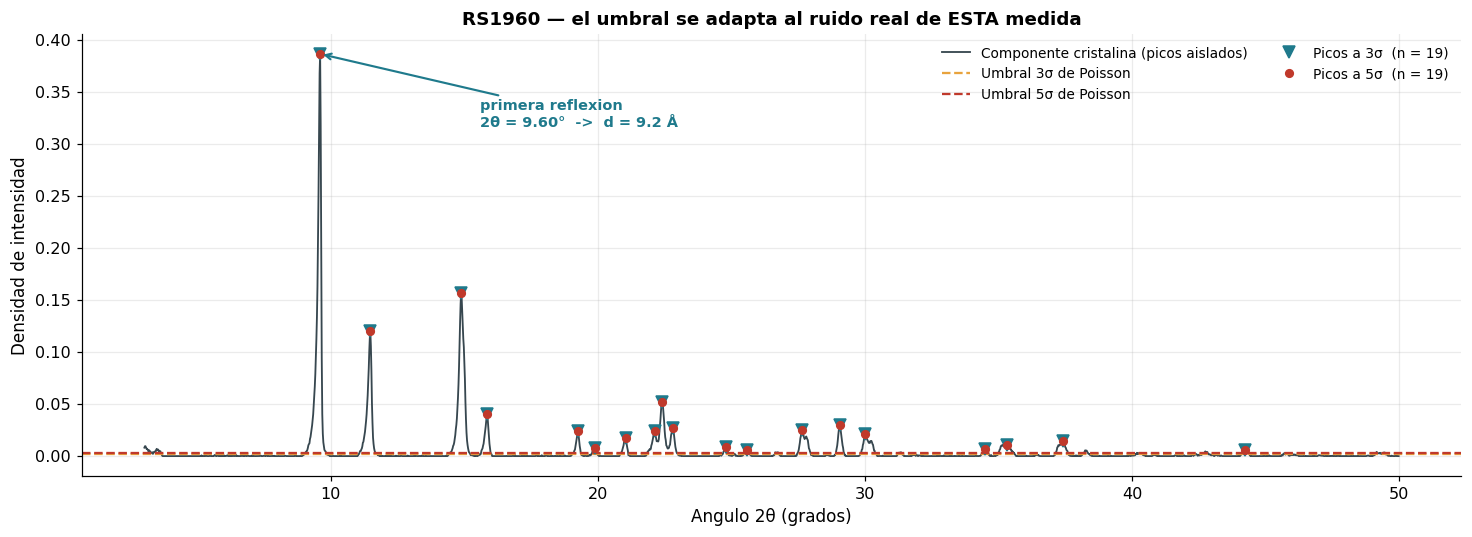

Nivel de ruido de Poisson de esta medida: 5.71e-04 (unidades normalizadas)
Picos a 3σ: 19     Picos a 5σ: 19
FWHM mediana: 0.158°     FWHM minima: 0.089°


In [13]:
x_pk, y_pk = cargar_curva(sample_code='RS1960')
capas_pk = decompose_profile(y_pk, x_pk)
ruido_pk = poisson_noise_level(y_pk, x_pk)

picos3, fwhm3 = detect_peaks_poisson(x_pk, capas_pk['crystalline'], ruido_pk, k_sigma=3.0)
picos5, fwhm5 = detect_peaks_poisson(x_pk, capas_pk['crystalline'], ruido_pk, k_sigma=5.0)

fig, ax = plt.subplots(figsize=(13.5, 5))
ax.plot(x_pk, capas_pk['crystalline'], color=C_CRUDO, lw=1.2, label='Componente cristalina (picos aislados)')
ax.axhline(3 * ruido_pk, color=C_AMORFO, ls='--', lw=1.5, label=f'Umbral 3σ de Poisson')
ax.axhline(5 * ruido_pk, color=C_PICO,   ls='--', lw=1.5, label=f'Umbral 5σ de Poisson')
ax.plot(x_pk[picos3], capas_pk['crystalline'][picos3], 'v', color=C_CRIST, ms=8,
        label=f'Picos a 3σ  (n = {len(picos3)})')
ax.plot(x_pk[picos5], capas_pk['crystalline'][picos5], 'o', color=C_PICO, ms=5,
        label=f'Picos a 5σ  (n = {len(picos5)})')

if len(picos3):
    i0 = picos3[0]
    d0 = WAVELENGTH_CU_KA1 / (2 * np.sin(np.radians(x_pk[i0] / 2)))
    ax.annotate(f'primera reflexion\n2θ = {x_pk[i0]:.2f}°  ->  d = {d0:.1f} Å',
                xy=(x_pk[i0], capas_pk['crystalline'][i0]),
                xytext=(x_pk[i0] + 6, capas_pk['crystalline'].max() * 0.82),
                fontsize=9.5, color=C_CRIST, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=C_CRIST, lw=1.4))

ax.set_title('RS1960 — el umbral se adapta al ruido real de ESTA medida', fontweight='bold')
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Densidad de intensidad')
ax.legend(fontsize=9, ncol=2)
plt.tight_layout(); plt.show()

print(f'Nivel de ruido de Poisson de esta medida: {ruido_pk:.2e} (unidades normalizadas)')
print(f'Picos a 3σ: {len(picos3):2d}     Picos a 5σ: {len(picos5):2d}')
print(f'FWHM mediana: {np.median(fwhm3):.3f}°     FWHM minima: {np.min(fwhm3):.3f}°')


---
# 8. El vector de descriptores

Aquí es donde la curva se convierte en una fila. Cada descriptor está elegido para
que **un químico lo pueda leer y defender ante un revisor**, no porque un
algoritmo lo pidiera.

## 8.1 El más importante: `d_max_angstrom`

La intuición de partida —*"ángulo bajo = celda grande = probable MOF poroso; ángulo
alto = óxido denso"*— es correcta, pero **en 2θ la relación no es lineal ni
intuitiva**. Al convertir con la ley de Bragg se vuelve directamente física:

$$d=\frac{\lambda}{2\sin\theta}\qquad(\lambda_{\text{Cu K}\alpha_1}=1{,}5406\ \text{Å})$$

| 2θ | d | Lectura química |
|---|---|---|
| 5° | 17,7 Å | Celda enorme — muy típico de MOF poroso |
| 10° | 8,8 Å | Celda grande |
| 20° | 4,4 Å | Intermedio |
| 30° | 3,0 Å | Rango típico de óxidos densos |

`d_max_angstrom` es **un solo número, en ångströms, que se lee de un vistazo**, y
probablemente el de mayor poder discriminante MOF / no-MOF de todo el vector.

## 8.2 El vector completo

| Descriptor | Qué mide | Para qué sirve |
|---|---|---|
| `n_peaks_k3` / `n_peaks_k5` | Reflexiones sobre 3σ / 5σ | Más reflexiones = más orden de largo alcance |
| `n_peaks_below_10deg` | Reflexiones a bajo ángulo | MOF poroso vs fase densa |
| `two_theta_first_peak` | Posición de la primera reflexión | Base de `d_max` |
| **`d_max_angstrom`** | Mayor espaciado interplanar | **El más discriminante para MOF** |
| `fwhm_median_deg`, `fwhm_min_deg` | Anchura de los picos | Calidad cristalina |
| `scherrer_size_nm` | Tamaño de dominio coherente | Semicuantitativo (ver aviso) |
| `crystalline_fraction` | A_crist / (A_crist + A_amorfo) | Grado de cristalinidad |
| `crystalline_area`, `amorphous_area` | Áreas de cada fase | **Conserva la info del amorfo** |
| `amorphous_hump_center`, `_fwhm` | Centro y anchura de la joroba | Naturaleza del amorfo |
| `frac_intensity_below_10deg` | Fracción de área bajo 10° | MOF vs óxido, **sin detectar picos** |
| `peak_to_background_ratio` | Contraste pico/fondo | Sensible al cristalino incipiente |
| `spectral_entropy` | Entropía de Shannon | Métrica global **sin detectar picos** |
| `snr_global` | Calidad de la medida | Control de calidad, no propiedad del material |
| `raw_counts_max` | Cuentas máximas brutas | Intensidad de adquisición |

> ⚠️ **Aviso obligatorio sobre Scherrer.** La fórmula $D=K\lambda/(\beta\cos\theta)$
> exige corregir el ensanchamiento instrumental ($\beta^2=\beta_{obs}^2-\beta_{inst}^2$),
> lo que requiere medir un patrón tipo LaB₆ o Si. **Aquí no se hace**, así que los
> tamaños salen sistemáticamente **subestimados**. Es válido como descriptor
> *comparativo* entre muestras medidas en el mismo equipo, y **nunca** debe
> presentarse como un tamaño de cristalito absoluto. Por eso la columna lleva ese
> aviso escrito en su `COMMENT` de SQL.
>
> (La propuesta anterior además decía en el texto que β era la *anchura integral*
> mientras el código pasaba la FWHM: no son lo mismo. Aquí se usa la FWHM, que es
> la convención que acompaña a K = 0,9.)

## 8.3 Un difractograma, anotado


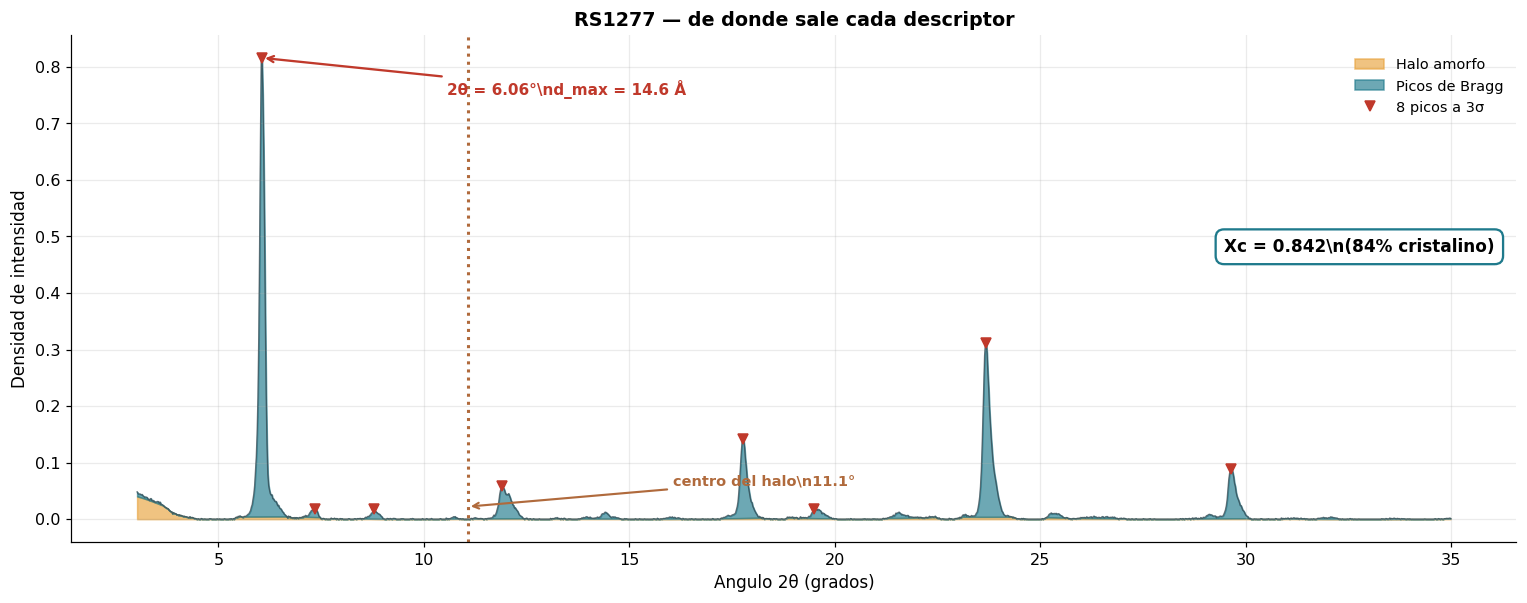

In [14]:
x_an, y_an = cargar_curva(sample_code='RS1277')
d_an = extract_descriptors(x_an, y_an, sample_code='RS1277', return_curves=True)
c_an = d_an['_curves']

fig, ax = plt.subplots(figsize=(14, 5.6))
ax.fill_between(x_an, 0, c_an['amorphous'], color=C_AMORFO, alpha=0.65, label='Halo amorfo')
ax.fill_between(x_an, c_an['amorphous'], c_an['amorphous'] + c_an['crystalline'],
                color=C_CRIST, alpha=0.65, label='Picos de Bragg')
ax.plot(x_an, c_an['net'], color=C_CRUDO, lw=0.9, alpha=0.7)

pk = c_an['peaks']
ax.plot(x_an[pk], c_an['net'][pk], 'v', color=C_PICO, ms=7, label=f"{d_an['n_peaks_k3']} picos a 3σ")

# Anotacion 1: primera reflexion -> d_max
if len(pk):
    ax.annotate(f"2θ = {d_an['two_theta_first_peak']:.2f}°\\nd_max = {d_an['d_max_angstrom']:.1f} Å",
                xy=(x_an[pk[0]], c_an['net'][pk[0]]),
                xytext=(x_an[pk[0]] + 4.5, c_an['net'].max() * 0.92),
                fontsize=10, fontweight='bold', color=C_PICO,
                arrowprops=dict(arrowstyle='->', color=C_PICO, lw=1.5))

# Anotacion 2: centro de la joroba
ax.axvline(d_an['amorphous_hump_center'], color=C_INSTR, ls=':', lw=2)
ax.annotate(f"centro del halo\\n{d_an['amorphous_hump_center']:.1f}°",
            xy=(d_an['amorphous_hump_center'], c_an['amorphous'].max() * 0.55),
            xytext=(d_an['amorphous_hump_center'] + 5, c_an['amorphous'].max() * 1.5),
            fontsize=9.5, color=C_INSTR, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=C_INSTR, lw=1.4))

# Anotacion 3: areas
ax.text(0.985, 0.60,
        f"Xc = {d_an['crystalline_fraction']:.3f}\\n"
        f"({100*d_an['crystalline_fraction']:.0f}% cristalino)",
        transform=ax.transAxes, ha='right', va='top', fontsize=11, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', fc='white', ec=C_CRIST, lw=1.5))

ax.set_title('RS1277 — de donde sale cada descriptor', fontweight='bold', fontsize=12.5)
ax.set_xlabel('Angulo 2θ (grados)'); ax.set_ylabel('Densidad de intensidad')
ax.legend(fontsize=9.5, loc='upper right', bbox_to_anchor=(1.0, 0.98))
plt.tight_layout(); plt.show()


In [15]:
# El vector completo de esta muestra, en formato legible
vector = {k: v for k, v in d_an.items() if not k.startswith('_')}
tabla_vector = pd.DataFrame({'valor': pd.Series(vector)})
display(tabla_vector)


,valor
sample_code,RS1277
pipeline_version,v1.0
baseline_method,arpls
baseline_lambda,1000000.0
broad_width_deg,3.0
peak_sigma_k,3.0
n_peaks_k3,8
n_peaks_k5,8
n_peaks_below_10deg,3
two_theta_first_peak,6.06


---
# 9. Los tres errores de cálculo, demostrados con números

Estos tres fallos estaban en la propuesta anterior. No se corrigen "porque sí": se
demuestra que dan números imposibles o inútiles.

## 9.1 El centro de la joroba salía ×50

La fórmula anterior era:

```python
amorphous_hump_center = np.sum(grid * y_signal) / (total_signal_area + 1e-12)
```

El numerador es un **sumatorio** ($\sum 2\theta_i \cdot y_i$) y el denominador una
**integral trapezoidal** ($\int y\,d2\theta$). No son magnitudes homogéneas: la
integral lleva dentro el paso $\Delta 2\theta = 0{,}02$, y el sumatorio no. Al
dividir una por otra, el resultado sale multiplicado por $1/0{,}02 = 50$.

Un centroide correcto se calcula con **integrales en ambos lados**, y entonces el
paso se cancela solo:

$$\text{centro}=\frac{\int 2\theta\cdot y(2\theta)\,d2\theta}{\int y(2\theta)\,d2\theta}$$


In [16]:
halo = c_an['amorphous']

centro_malo  = float(np.sum(x_an * halo) / (integrate(halo, x_an) + 1e-12))
centro_bueno = float(integrate(x_an * halo, x_an) / integrate(halo, x_an))

print(f'Formula anterior (suma / integral) : {centro_malo:10.2f} grados 2θ')
print(f'Centroide correcto (int / int)     : {centro_bueno:10.2f} grados 2θ')
print(f'Factor de error                    : {centro_malo/centro_bueno:10.1f}x   (= 1/paso = {1/0.02:.0f})')
print()
print(f'El valor de la formula anterior es fisicamente imposible: 2θ no puede')
print(f'pasar de 180 grados, y esta formula devuelve {centro_malo:.0f}.')


Formula anterior (suma / integral) :     554.52 grados 2θ
Centroide correcto (int / int)     :      11.06 grados 2θ
Factor de error                    :       50.1x   (= 1/paso = 50)

El valor de la formula anterior es fisicamente imposible: 2θ no puede
pasar de 180 grados, y esta formula devuelve 555.


## 9.2 `snr_global` era una copia disfrazada de otro descriptor

La fórmula anterior era `raw_counts_max / sqrt(raw_counts_max)`, que simplificando
es **exactamente** `sqrt(raw_counts_max)`.

Es decir, no era una relación señal/ruido: era la raíz cuadrada de un descriptor
que ya estaba en el vector. Para un modelo de ML son dos columnas perfectamente
colineales, y encima el nombre engaña: un difractograma de **puro ruido** con
muchas cuentas obtendría un "SNR excelente".


In [17]:
for cuentas in (100.0, 10_000.0):
    print(f'raw_counts_max = {cuentas:>8,.0f}  ->  formula anterior = {cuentas/np.sqrt(cuentas):>7.1f}'
          f'   |   sqrt(raw_counts_max) = {np.sqrt(cuentas):>7.1f}   <- identicos')

print()
print('SNR real (señal neta / ruido de Poisson), que si mide algo del patron:')
print(f"  RS1277 -> {d_an['snr_global']:.1f}")


raw_counts_max =      100  ->  formula anterior =    10.0   |   sqrt(raw_counts_max) =    10.0   <- identicos
raw_counts_max =   10,000  ->  formula anterior =   100.0   |   sqrt(raw_counts_max) =   100.0   <- identicos

SNR real (señal neta / ruido de Poisson), que si mide algo del patron:
  RS1277 -> 1015.7


## 9.3 `fwhm_min` se calculaba y se tiraba

En la versión anterior la línea `fwhm_min = float(np.min(fwhm_k3))` existía, pero
la variable no aparecía en el diccionario devuelto. El roadmap la pide
explícitamente, y es útil porque es **menos sensible que la mediana** a los hombros
mal resueltos. Aquí está incluida.


In [18]:
print(f"fwhm_median_deg = {d_an['fwhm_median_deg']:.4f}°")
print(f"fwhm_min_deg    = {d_an['fwhm_min_deg']:.4f}°   <- ahora si se devuelve")


fwhm_median_deg = 0.2004°
fwhm_min_deg    = 0.1418°   <- ahora si se devuelve


---
# 10. Escribir en `pxrd_descriptors`

Ya tenemos el método validado. Ahora hay que dejar los números **en la base de
datos**, que es donde los podrá leer la app web, el agente RAG y el modelo de ML.

## 10.1 Las dos tablas nuevas

El DDL está en [`scripts/ddl_pxrd_descriptors.sql`](../scripts/ddl_pxrd_descriptors.sql).

**`pxrd_descriptors`** — una fila por medida, con el vector completo. Lo importante
son las **columnas de trazabilidad**: `pipeline_version`, `baseline_method`,
`baseline_lambda`, `broad_width_deg`, `peak_sigma_k`.

> No son burocracia. Cuando dentro de tres meses se recalculen los descriptores con
> otro λ, esas columnas son **lo único** que permitirá saber qué filas son
> comparables entre sí. Es el mismo principio de trazabilidad del `audit_log`.

**`pxrd_labels`** — las etiquetas (AMORFO / INCIPIENTE / CRISTALINO, y en el futuro
el triaje de novedad). Va en tabla aparte, y no como columna de la anterior, por
tres razones: los descriptores se recalculan solos mientras que las etiquetas son
juicio humano caro que debe sobrevivir a esos recálculos; una medida puede llevar
varios tipos de etiqueta a la vez; y una etiqueta necesita su propia procedencia
(quién lo dijo, cuándo, con qué seguridad).

> **Una corrección respecto al borrador del roadmap.** Allí la clave foránea se
> escribía `measurement_id INTEGER REFERENCES characterization_measurements(id)`.
> Las dos mitades están mal contra el esquema real: la clave primaria se llama
> `measurement_id`, no `id`, y es un **UUID**, no un entero. Copiado literal, el
> `CREATE TABLE` habría fallado.


In [19]:
estructura = sql("""
    SELECT c.column_name AS columna, c.data_type AS tipo,
           COALESCE(d.description, '(sin describir)') AS descripcion
    FROM information_schema.columns c
    LEFT JOIN data_dictionary d
           ON d.table_name = c.table_name AND d.column_name = c.column_name
    WHERE c.table_name = 'pxrd_descriptors'
    ORDER BY c.ordinal_position;
""")
pd.set_option('display.max_colwidth', 70)
display(estructura)
print(f"Columnas sin describir en data_dictionary: "
      f"{(estructura['descripcion'] == '(sin describir)').sum()}")


,columna,tipo,descripcion
0,measurement_id,uuid,Measurement this descriptor vector was computed from.
1,sample_code,character varying,"Sample the measurement belongs to, denormalised for convenient gro..."
2,pipeline_version,character varying,Version of the descriptor pipeline. Rows computed under different ...
3,baseline_method,character varying,Baseline estimation algorithm used.
4,baseline_lambda,double precision,Smoothing parameter of the rigid pass that removes only the instru...
5,broad_width_deg,double precision,Width of the running-median window that separates the broad amorph...
6,peak_sigma_k,double precision,Poisson significance multiplier used for the primary peak count.
7,n_peaks_k3,integer,Reflections detected above a 3-sigma Poisson prominence threshold.
8,n_peaks_k5,integer,Reflections detected above a stricter 5-sigma threshold.
9,n_peaks_below_10deg,integer,"Reflections below 10 degrees 2-theta, indicating large unit cells."


Columnas sin describir en data_dictionary: 0


## 10.2 Calcular y guardar un lote

Procesamos un lote representativo del corpus para dejar el circuito completo
funcionando de punta a punta. El proceso del corpus entero se hace aparte, con un
script en batch, porque no es trabajo de un cuaderno.

El `INSERT` usa `ON CONFLICT (measurement_id) DO UPDATE`, es decir un **UPSERT**:
si la medida ya tenía descriptores, se actualizan; si no, se insertan. Así el
cuaderno se puede reejecutar tantas veces como haga falta sin duplicar nada y sin
tener que borrar antes.


In [20]:
TAMANO_LOTE = 300

pendientes = sql("""
    SELECT m.measurement_id::text AS measurement_id,
           m.sample_code,
           m.data_json->'raw_data'->>'x' AS x,
           m.data_json->'raw_data'->>'y' AS y
    FROM characterization_measurements m
    WHERE m.technique = 'PXRD'
      AND jsonb_array_length(m.data_json->'raw_data'->'x') > 100
    ORDER BY m.sample_code
    LIMIT %(lote)s;
""", params={'lote': TAMANO_LOTE})

print(f'{len(pendientes)} medidas a procesar')

resultados, fallos = [], []
for fila in pendientes.itertuples():
    try:
        xb = np.array(json.loads(fila.x), dtype=float)
        yb = np.array(json.loads(fila.y), dtype=float)
        rejilla, y_rej, valido = resample_to_grid(xb, yb)
        if valido.sum() < 100:
            fallos.append((fila.sample_code, 'rango angular insuficiente')); continue
        d = extract_descriptors(rejilla[valido], y_rej[valido], sample_code=fila.sample_code)
        d['measurement_id'] = fila.measurement_id
        resultados.append(d)
    except Exception as exc:
        fallos.append((fila.sample_code, str(exc)[:60]))

print(f'Calculados: {len(resultados)}    Fallidos: {len(fallos)}')
if fallos:
    for c, e in fallos[:5]:
        print(f'   {c}: {e}')


300 medidas a procesar


Calculados: 300    Fallidos: 0


In [21]:
COLUMNAS = ['measurement_id', 'sample_code'] + DESCRIPTOR_COLUMNS

INSERTAR = f"""
    INSERT INTO pxrd_descriptors ({', '.join(COLUMNAS)})
    VALUES ({', '.join(['%s'] * len(COLUMNAS))})
    ON CONFLICT (measurement_id) DO UPDATE SET
        {', '.join(f'{c} = EXCLUDED.{c}' for c in COLUMNAS if c != 'measurement_id')},
        computed_at = now();
"""

def limpio(v):
    """NaN/inf de numpy no son validos en SQL: se guardan como NULL."""
    if isinstance(v, (float, np.floating)):
        return None if (np.isnan(v) or np.isinf(v)) else float(v)
    if isinstance(v, (int, np.integer)):
        return int(v)
    return v

with conectar() as conn:
    cur = conn.cursor()
    for d in resultados:
        cur.execute(INSERTAR, [limpio(d[c]) for c in COLUMNAS])
    conn.commit()

print(f'{len(resultados)} filas escritas en pxrd_descriptors.')


300 filas escritas en pxrd_descriptors.


In [22]:
verificacion = sql("""
    SELECT count(*)                                AS filas,
           count(DISTINCT sample_code)             AS muestras,
           round(avg(crystalline_fraction)::numeric, 3) AS xc_medio,
           round(min(crystalline_fraction)::numeric, 3) AS xc_min,
           round(max(crystalline_fraction)::numeric, 3) AS xc_max,
           round(avg(d_max_angstrom)::numeric, 2)  AS d_max_medio,
           max(pipeline_version)                   AS version,
           max(baseline_lambda)                    AS lambda
    FROM pxrd_descriptors;
""")
display(verificacion)

print('Comprobacion de que la clave foranea funciona (JOIN con la tabla padre):')
display(sql("""
    SELECT d.sample_code, m.file_name,
           d.n_peaks_k3, round(d.crystalline_fraction::numeric, 3) AS xc,
           round(d.d_max_angstrom::numeric, 2) AS d_max_A
    FROM pxrd_descriptors d
    JOIN characterization_measurements m USING (measurement_id)
    ORDER BY d.crystalline_fraction DESC
    LIMIT 5;
"""))


,filas,muestras,xc_medio,xc_min,xc_max,d_max_medio,version,lambda
0,300,295,0.48,0.222,0.954,23.68,v1.0,1000000.0


Comprobacion de que la clave foranea funciona (JOIN con la tabla padre):


,sample_code,file_name,n_peaks_k3,xc,d_max_a
0,REF-DRX-26376-11-Patr-n,DRX-26376(11)-Patrón.xrdml,2,0.954,3.14
1,REF-DRX-21237-9-Cu-NO3-2-3H2O,DRX-21237(9)-Cu(NO3)2-3H2O.xrdml,5,0.889,5.90
2,REF-DRX-26376-10-Blanco,DRX-26376(10)-Blanco.xrdml,4,0.887,16.72
3,REF-DRX-21219-7-Ni-NO3-2-6H2O,DRX-21219(7)-Ni(NO3)2-6H2O.xrdml,12,0.830,10.77
4,RS1074,DRX-22144(4)-RS1074-NiPyF2.xrdml,27,0.826,25.08


---
# 11. Qué dicen los datos

Con los descriptores ya en la base de datos, las preguntas se responden con SQL.
Esto es lo que se ha ganado: hasta ahora, "dame las muestras con celda unidad
grande y poca cristalinidad" no era una pregunta que se pudiera hacer.


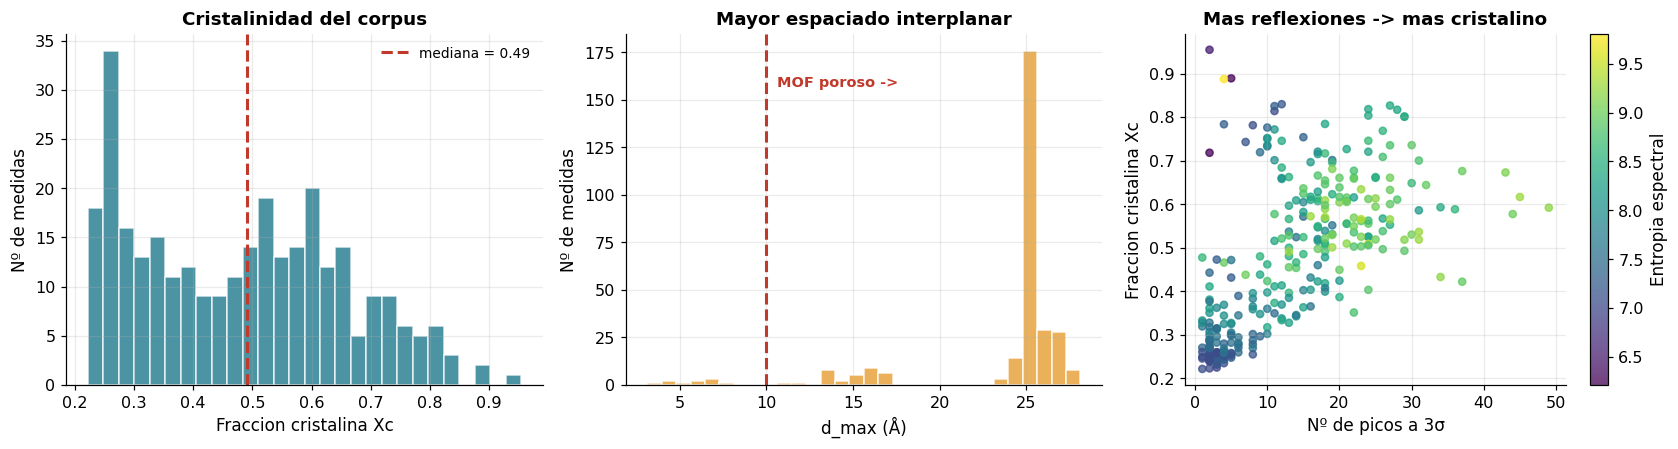

Correlaciones entre descriptores:


,xc,n_picos,entropia,fwhm
xc,1.000,0.600,0.486,0.408
n_picos,0.600,1.000,0.739,0.252
entropia,0.486,0.739,1.000,0.410
fwhm,0.408,0.252,0.410,1.000


In [23]:
distribucion = sql("""
    SELECT crystalline_fraction AS xc, d_max_angstrom AS d_max,
           n_peaks_k3 AS n_picos, spectral_entropy AS entropia,
           fwhm_median_deg AS fwhm, amorphous_hump_center AS centro_halo
    FROM pxrd_descriptors
    WHERE crystalline_fraction IS NOT NULL;
""")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))

ax = axes[0]
ax.hist(distribucion['xc'].dropna(), bins=28, color=C_CRIST, alpha=0.8, edgecolor='white')
ax.axvline(distribucion['xc'].median(), color=C_PICO, ls='--', lw=2,
           label=f"mediana = {distribucion['xc'].median():.2f}")
ax.set_title('Cristalinidad del corpus', fontweight='bold')
ax.set_xlabel('Fraccion cristalina Xc'); ax.set_ylabel('Nº de medidas'); ax.legend(fontsize=9)

ax = axes[1]
d_validos = distribucion['d_max'].dropna()
d_validos = d_validos[(d_validos > 0) & (d_validos < 40)]
ax.hist(d_validos, bins=30, color=C_AMORFO, alpha=0.85, edgecolor='white')
ax.axvline(10, color=C_PICO, ls='--', lw=2)
ax.text(10.6, ax.get_ylim()[1]*0.85, 'MOF poroso ->', color=C_PICO, fontsize=9.5, fontweight='bold')
ax.set_title('Mayor espaciado interplanar', fontweight='bold')
ax.set_xlabel('d_max (Å)'); ax.set_ylabel('Nº de medidas')

ax = axes[2]
sc = ax.scatter(distribucion['n_picos'], distribucion['xc'],
                c=distribucion['entropia'], cmap='viridis', s=22, alpha=0.75)
ax.set_title('Mas reflexiones -> mas cristalino', fontweight='bold')
ax.set_xlabel('Nº de picos a 3σ'); ax.set_ylabel('Fraccion cristalina Xc')
plt.colorbar(sc, ax=ax, label='Entropia espectral')

plt.tight_layout(); plt.show()

corr = distribucion[['xc', 'n_picos', 'entropia', 'fwhm']].corr()
print('Correlaciones entre descriptores:')
display(corr.round(3))


**Cómo leer esto.**

- **Izquierda.** La cristalinidad se reparte por todo el rango. Eso es exactamente
  lo que debe pasar en un corpus real de 5 años: hay síntesis que salieron bien,
  otras que salieron amorfas y muchas intermedias. Si todo saliera 1,00 (como
  pasaba con el método anterior), el descriptor no serviría para nada.
- **Centro.** Buena parte del corpus está por encima de 10 Å, la firma de una celda
  unidad expandida — coherente con un laboratorio que hace MOFs porosos.
- **Derecha.** Más reflexiones detectadas se asocia con mayor fracción cristalina,
  que es la comprobación de coherencia interna que uno espera: dos descriptores
  calculados por caminos independientes (uno cuenta picos, el otro integra áreas)
  apuntan en la misma dirección.

**Sobre la entropía, un resultado contraintuitivo.** El manual dice que un patrón
"ordenado" debería tener entropía *baja*. En estos datos pasa lo contrario: la
entropía **sube** con la cristalinidad (correlación ≈ +0,7). Y tiene sentido
físico: una muestra amorfa concentra toda su intensidad neta en **una sola joroba**
(distribución concentrada → entropía baja), mientras que una muestra bien
cristalizada la reparte entre **muchas reflexiones a lo largo de todo el rango**
(distribución extendida → entropía alta). El descriptor discrimina igual de bien;
lo que había que corregir era la *descripción* de lo que mide.

---

# Cierre

## Lo que queda montado

1. **1.859 medidas PXRD y 13 patrones de referencia** ingestados en PostgreSQL. La
   base de datos ya es la fuente de verdad; este cuaderno no abre ni un fichero.
2. **λ calibrado de verdad** (etapa E1 del roadmap, la bloqueante) contra el blanco,
   una muestra amorfa y una cristalina reales: **λ = 10⁶**, no 10⁷.
3. **Separación halo/picos por anchura**, que es lo que hace que `crystalline_fraction`
   signifique algo.
4. **Tres errores de cálculo corregidos** y demostrados numéricamente.
5. **`pxrd_descriptors` y `pxrd_labels` creadas, documentadas** en `data_dictionary`
   y alimentadas.

## Siguientes pasos

- **E0 completo** — pasar el script en batch sobre las 1.859 medidas (fuera del
  cuaderno). Con ~0,02 s por patrón, es cosa de un minuto.
- **E2 — etiquetado.** Las etiquetas humanas van a `pxrd_labels`. Sin ellas no hay
  modelo supervisado posible.
- **E3 — NMF** sobre la matriz completa, para rellenar `nmf_weights`.
- **Sección 5-bis del roadmap — el triaje de NOVEDAD.** Esta es la que de verdad
  importa: comparar **posiciones** de pico contra las estructuras propias resueltas
  por SCXRD. Los 10 CIFs ya están en `data/reference_libraries/PXRD/simulated_scxrd/`
  y el parser `src/parse_cif_scxrd.py` ya existe. Según el propio roadmap, el target
  real no es la cristalinidad sino la novedad, y ese es el producto final.
- **El modelo de ML va al final**, y solo después de tener etiquetas.
